In [1]:
from google.colab import files
uploaded = files.upload()

Saving faculty_consultations.csv to faculty_consultations.csv


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load dataset
df = pd.read_csv("faculty_consultations.csv")

print("Dataset Shape:", df.shape)
display(df.head())

# Required columns
required_columns = [
    "Faculty",
    "Day",
    "TimeSlot",
    "StudentYear",
    "Duration",
    "CurrentBookings",
    "SlotAvailable"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in the dataset: {missing_columns}"
    )

# Convert target values into 1 and 0
df["Target"] = df["SlotAvailable"].apply(
    lambda value: 1
    if str(value).strip().lower() == "yes"
    else 0
)

# Features and target
features = [
    "Faculty",
    "Day",
    "TimeSlot",
    "StudentYear",
    "Duration",
    "CurrentBookings"
]

X = df[features]
y = df["Target"]

# Separate categorical and numerical columns
categorical_features = [
    "Faculty",
    "Day",
    "TimeSlot"
]

numerical_features = [
    "StudentYear",
    "Duration",
    "CurrentBookings"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Decision Tree model
decision_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(random_state=42)
        )
    ]
)

# Logistic Regression model
logistic_regression = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(max_iter=500)
        )
    ]
)

# Train both models
decision_tree.fit(X_train, y_train)
logistic_regression.fit(X_train, y_train)

# Predictions
dt_predictions = decision_tree.predict(X_test)
lr_predictions = logistic_regression.predict(X_test)

# Accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("===== MODEL COMPARISON =====")
print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")
print(f"Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%")

# Decision Tree results
print("\n===== DECISION TREE =====")
print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        dt_predictions,
        target_names=["Unavailable", "Available"],
        zero_division=0
    )
)

# Logistic Regression results
print("\n===== LOGISTIC REGRESSION =====")
print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Unavailable", "Available"],
        zero_division=0
    )
)

Dataset Shape: (80, 7)


,Faculty,Day,TimeSlot,StudentYear,Duration,CurrentBookings,SlotAvailable
0,Prof. Santos,Monday,15:00,3,30,0,Yes
1,Prof. Dela Rosa,Monday,14:00,4,15,0,Yes
2,Prof. Dela Rosa,Friday,9:00,2,60,1,No
3,Prof. Cruz,Monday,10:00,4,30,0,Yes
4,Prof. Cruz,Monday,9:00,4,15,1,Yes


===== MODEL COMPARISON =====
Decision Tree Accuracy: 83.33%
Logistic Regression Accuracy: 91.67%

===== DECISION TREE =====
Confusion Matrix:
[[ 8  2]
 [ 2 12]]

Classification Report:
              precision    recall  f1-score   support

 Unavailable       0.80      0.80      0.80        10
   Available       0.86      0.86      0.86        14

    accuracy                           0.83        24
   macro avg       0.83      0.83      0.83        24
weighted avg       0.83      0.83      0.83        24


===== LOGISTIC REGRESSION =====
              precision    recall  f1-score   support

 Unavailable       1.00      0.80      0.89        10
   Available       0.88      1.00      0.93        14

    accuracy                           0.92        24
   macro avg       0.94      0.90      0.91        24
weighted avg       0.93      0.92      0.91        24



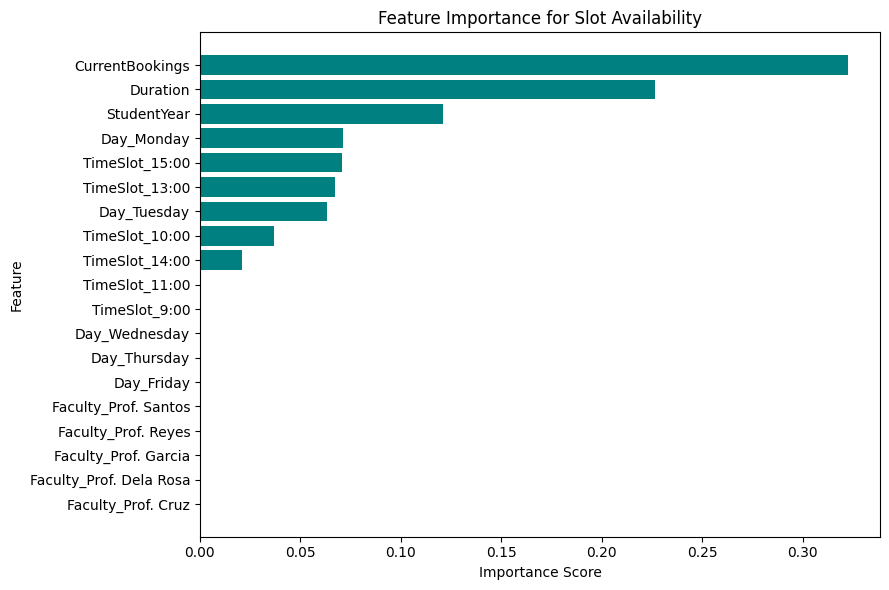

In [3]:
# Get encoded feature names
trained_preprocessor = decision_tree.named_steps["preprocessor"]
tree_model = decision_tree.named_steps["model"]

encoded_features = (
    list(
        trained_preprocessor
        .named_transformers_["categorical"]
        .get_feature_names_out(categorical_features)
    )
    + numerical_features
)

importance_values = tree_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": encoded_features,
    "Importance": importance_values
}).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    color="teal"
)

plt.title("Feature Importance for Slot Availability")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [4]:
%%writefile app.py
import streamlit as st
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

st.set_page_config(
    page_title="Faculty Consultation Checker",
    page_icon="📚"
)

st.title("Faculty Consultation Slot Checker")
st.write(
    "Enter the consultation details to check if the slot is available."
)

#file uploader
uploaded_file = st.file_uploader(
    "Upload faculty_consultations.csv",
    type=["csv"]
)

if uploaded_file is None:
    st.info("Please upload the CSV dataset to continue.")
    st.stop()

df = pd.read_csv(uploaded_file)

required_columns = [
    "Faculty",
    "Day",
    "TimeSlot",
    "StudentYear",
    "Duration",
    "CurrentBookings",
    "SlotAvailable"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    st.error(f"Missing columns: {missing_columns}")
    st.stop()

#availability
df["Target"] = df["SlotAvailable"].apply(
    lambda value: 1
    if str(value).strip().lower() == "yes"
    else 0
)

features = [
    "Faculty",
    "Day",
    "TimeSlot",
    "StudentYear",
    "Duration",
    "CurrentBookings"
]

X = df[features]
y = df["Target"]

categorical_features = [
    "Faculty",
    "Day",
    "TimeSlot"
]

numerical_features = [
    "StudentYear",
    "Duration",
    "CurrentBookings"
]

#pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

#decision tree
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(random_state=42)
        )
    ]
)

model.fit(X, y)

st.subheader("Consultation Details")

faculty = st.selectbox(
    "Faculty",
    sorted(df["Faculty"].dropna().unique())
)

day = st.selectbox(
    "Day",
    sorted(df["Day"].dropna().unique())
)

time_slot = st.selectbox(
    "Time Slot",
    sorted(df["TimeSlot"].dropna().unique())
)

student_year = st.number_input(
    "Student Year",
    min_value=1,
    max_value=6,
    value=1,
    step=1
)

duration = st.number_input(
    "Duration in minutes",
    min_value=1,
    value=30,
    step=5
)

current_bookings = st.number_input(
    "Current Bookings",
    min_value=0,
    value=0,
    step=1
)

input_data = pd.DataFrame({
    "Faculty": [faculty],
    "Day": [day],
    "TimeSlot": [time_slot],
    "StudentYear": [student_year],
    "Duration": [duration],
    "CurrentBookings": [current_bookings]
})

if st.button("Check Availability"):
    prediction = model.predict(input_data)[0]

    if prediction == 1:
        st.success("The consultation slot is predicted to be AVAILABLE.")
    else:
        st.error("The consultation slot is predicted to be UNAVAILABLE.")

Writing app.py


In [17]:
!pip install -q streamlit

In [18]:
!streamlit run app.py &>/content/streamlit.log &

In [23]:
!pkill -f streamlit

!streamlit run app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [27]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>